<a href="https://colab.research.google.com/github/Adrentur/-1_-_-_-3-10/blob/main/%D0%9B%D0%A0_10_%D0%9F%D0%BE%D0%BB%D0%B5%D1%85%D1%96%D0%BD_%D0%84%D0%B3%D0%BE%D1%80_3-10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** ______________________________  
**Група:** ______________________________  
**Дата:** ______________________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report

# Фіксація зерна генератора випадкових чисел для відтворюваності
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top",  # 0 — Футболка / топ
    "Trouser",      # 1 — Штани / брюки
    "Pullover",     # 2 — Пуловер / светр
    "Dress",        # 3 — Сукня
    "Coat",         # 4 — Пальто
    "Sandal",       # 5 — Сандалі
    "Shirt",        # 6 — Сорочка
    "Sneaker",      # 7 — Кросівки
    "Bag",          # 8 — Сумка
    "Ankle boot"    # 9 — Черевики до щиколотки
]

print("x_train_raw shape:", x_train_raw.shape, "dtype:", x_train_raw.dtype)
print("y_train_raw shape:", y_train_raw.shape, "dtype:", y_train_raw.dtype)
print("x_test_raw shape: ", x_test_raw.shape,  "dtype:", x_test_raw.dtype)
print("y_test_raw shape: ", y_test_raw.shape,  "dtype:", y_test_raw.dtype)

x_train_raw shape: (60000, 28, 28) dtype: uint8
y_train_raw shape: (60000,) dtype: uint8
x_test_raw shape:  (10000, 28, 28) dtype: uint8
y_test_raw shape:  (10000,) dtype: uint8


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

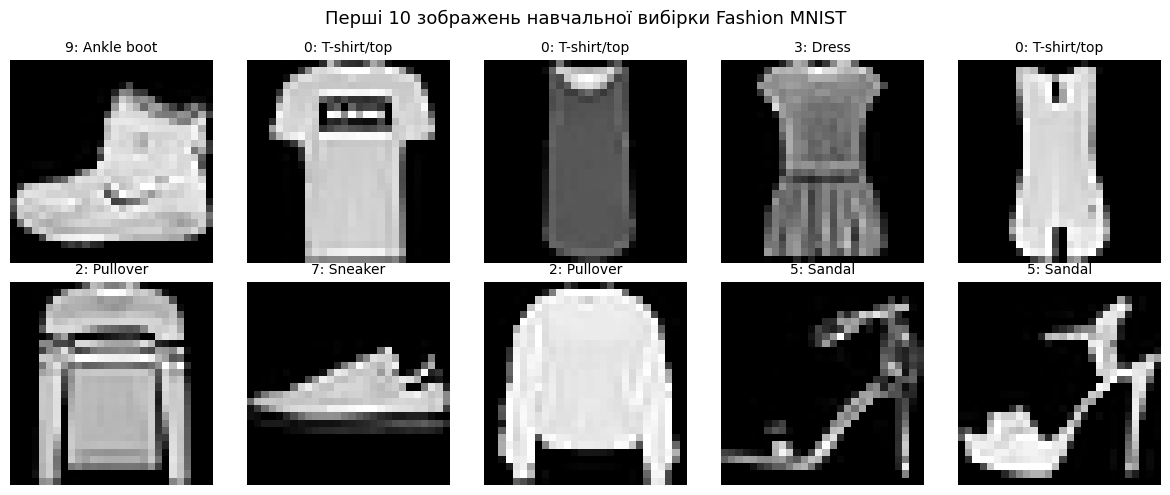

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_raw[i], cmap="gray")
    plt.title(f"{y_train_raw[i]}: {class_names[y_train_raw[i]]}", fontsize=10)
    plt.axis("off")

plt.suptitle("Перші 10 зображень навчальної вибірки Fashion MNIST", fontsize=13)
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train_raw.astype("float32") / 255.0
x_test = x_test_raw.astype("float32") / 255.0
y_train = y_train_raw.astype("int32")
y_test = y_test_raw.astype("int32")

print(f"x_train min/max: {x_train.min():.2f} / {x_train.max():.2f}, dtype: {x_train.dtype}")
print(f"x_test  min/max: {x_test.min():.2f} / {x_test.max():.2f}, dtype: {x_test.dtype}")

x_train min/max: 0.00 / 1.00, dtype: float32
x_test  min/max: 0.00 / 1.00, dtype: float32


### Крок 4. Побудова й компіляція моделі

Пояснення вибору гіперпараметрів:Кількість нейронів (512 → 256 → 128): вхідний вектор має розмірність $28 \times 28 = 784$. Поступове звуження розмірності (512 → 256 → 128) дозволяє спочатку виділити комбінації пікселів та локальні контури, а далі узагальнити їх до 10 класів без різкого «вузького місця».Активація ReLU та вихід softmax: ReLU ефективно бореться із зникненням градієнта та прискорює навчання повнозв’язних шарів; softmax на виході з 10 нейронів перетворює логіти на нормований розподіл імовірностей по класах.Регуляризація Dropout (0.3 та 0.2): випадкове вимкнення частини нейронів під час навчання зменшує коадаптацію ознак і запобігає перенавчанню на 60 000 зображеннях.Оптимізатор Adam та швидкість навчання (learning_rate = 1e-3): стандартне стартове значення 0.001 для Adam забезпечує стабільну та досить швидку збіжність, а подальше тонке підлаштування кроку доручено ReduceLROnPlateau.Функція втрат sparse_categorical_crossentropy: мітки y_train задані цілими числами 0..9 (не one-hot), тому ця функція втрат підходить напряму.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
def build_baseline_model(learning_rate=1e-3):
    model = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax")
    ], name="fashion_mnist_mlp")

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model_1 = build_baseline_model(learning_rate=1e-3)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_1 = model_1.fit(
    x_train,
    y_train,
    batch_size=128,
    epochs=40,
    validation_split=0.15,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("Фактична кількість епох навчання:", len(history_1.history["loss"]))

Epoch 1/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.7938 - loss: 0.5715 - val_accuracy: 0.8447 - val_loss: 0.4300 - learning_rate: 0.0010
Epoch 2/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8484 - loss: 0.4122 - val_accuracy: 0.8593 - val_loss: 0.3886 - learning_rate: 0.0010
Epoch 3/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 13s 31ms/step - accuracy: 0.8618 - loss: 0.3761 - val_accuracy: 0.8698 - val_loss: 0.3592 - learning_rate: 0.0010
Epoch 4/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8693 - loss: 0.3540 - val_accuracy: 0.8696 - val_loss: 0.3529 - learning_rate: 0.0010
Epoch 5/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8749 - loss: 0.3374 - val_accuracy: 0.8736 - val_loss: 0.3505 - learning_rate: 0.0010
Epoch 6/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.8804 - loss: 0.3240 - val_accuracy: 0.8731 - val_loss: 0.3394 - learning_rate: 0.0010
Epoch 7/40
399/399 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8846 - loss: 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model_1.summary()
print("Кількість шарів (включно з Input):", len(model_1.layers))
print("Загальна кількість параметрів:", model_1.count_params())

Model: "fashion_mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,702,304 (6.49 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,134,870 (4.33 MB)

Кількість шарів (включно з Input): 7
Загальна кількість параметрів: 567434


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model_path = "fashion_mnist_model_1.keras"
model_1.save(model_path)

from google.colab import files
files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

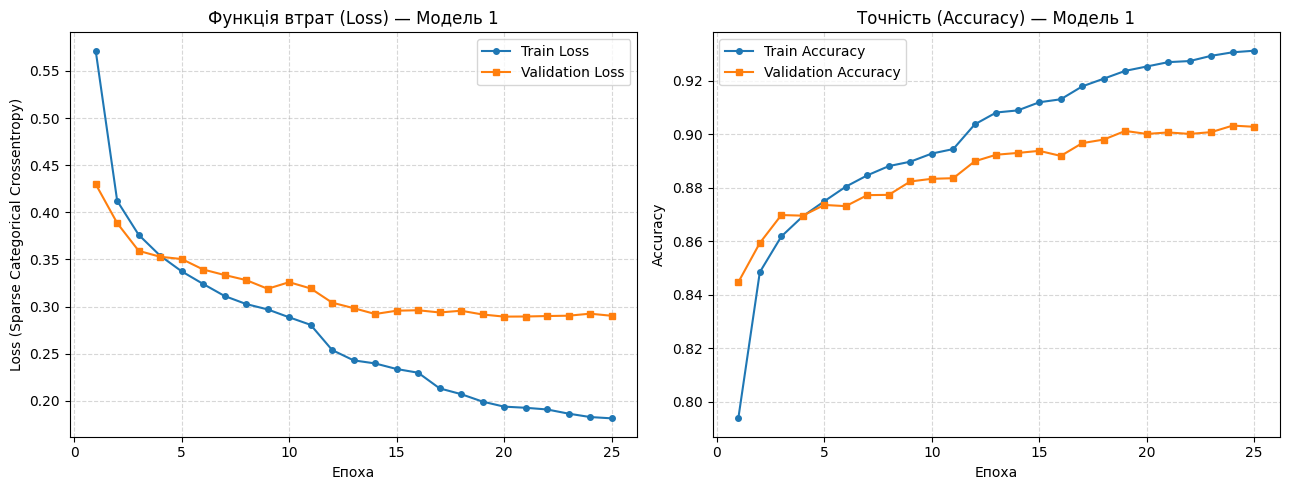

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
epochs_range_1 = range(1, len(history_1.history["loss"]) + 1)

plt.figure(figsize=(13, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)
plt.plot(epochs_range_1, history_1.history["loss"], label="Train Loss", marker="o", markersize=4)
plt.plot(epochs_range_1, history_1.history["val_loss"], label="Validation Loss", marker="s", markersize=4)
plt.title("Функція втрат (Loss) — Модель 1")
plt.xlabel("Епоха")
plt.ylabel("Loss (Sparse Categorical Crossentropy)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Графік точності
plt.subplot(1, 2, 2)
plt.plot(epochs_range_1, history_1.history["accuracy"], label="Train Accuracy", marker="o", markersize=4)
plt.plot(epochs_range_1, history_1.history["val_accuracy"], label="Validation Accuracy", marker="s", markersize=4)
plt.title("Точність (Accuracy) — Модель 1")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss_1, test_acc_1 = model_1.evaluate(x_test, y_test, verbose=0)
print(f"Тестові втрати (loss): {test_loss_1:.4f}")
print(f"Тестова точність (accuracy): {test_acc_1:.4f}")
print(f"Поріг 0.87 досягнуто: {'ТАК' if test_acc_1 >= 0.87 else 'НІ'}")

y_pred_probs_1 = model_1.predict(x_test, verbose=0)
y_pred_1 = np.argmax(y_pred_probs_1, axis=1)

print("\nКласифікаційний звіт (Модель 1):")
print(classification_report(y_test, y_pred_1, target_names=class_names, digits=4))

Тестові втрати (loss): 0.3111
Тестова точність (accuracy): 0.8961
Поріг 0.87 досягнуто: ТАК

Класифікаційний звіт (Модель 1):
              precision    recall  f1-score   support

 T-shirt/top     0.8451    0.8620    0.8535      1000
     Trouser     0.9878    0.9730    0.9804      1000
    Pullover     0.7945    0.8160    0.8051      1000
       Dress     0.8901    0.9150    0.9024      1000
        Coat     0.8043    0.8180    0.8111      1000
      Sandal     0.9838    0.9690    0.9763      1000
       Shirt     0.7629    0.6950    0.7274      1000
     Sneaker     0.9464    0.9710    0.9585      1000
         Bag     0.9712    0.9790    0.9751      1000
  Ankle boot     0.9698    0.9630    0.9664      1000

    accuracy                         0.8961     10000
   macro avg     0.8956    0.8961    0.8956     10000
weighted avg     0.8956    0.8961    0.8956     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

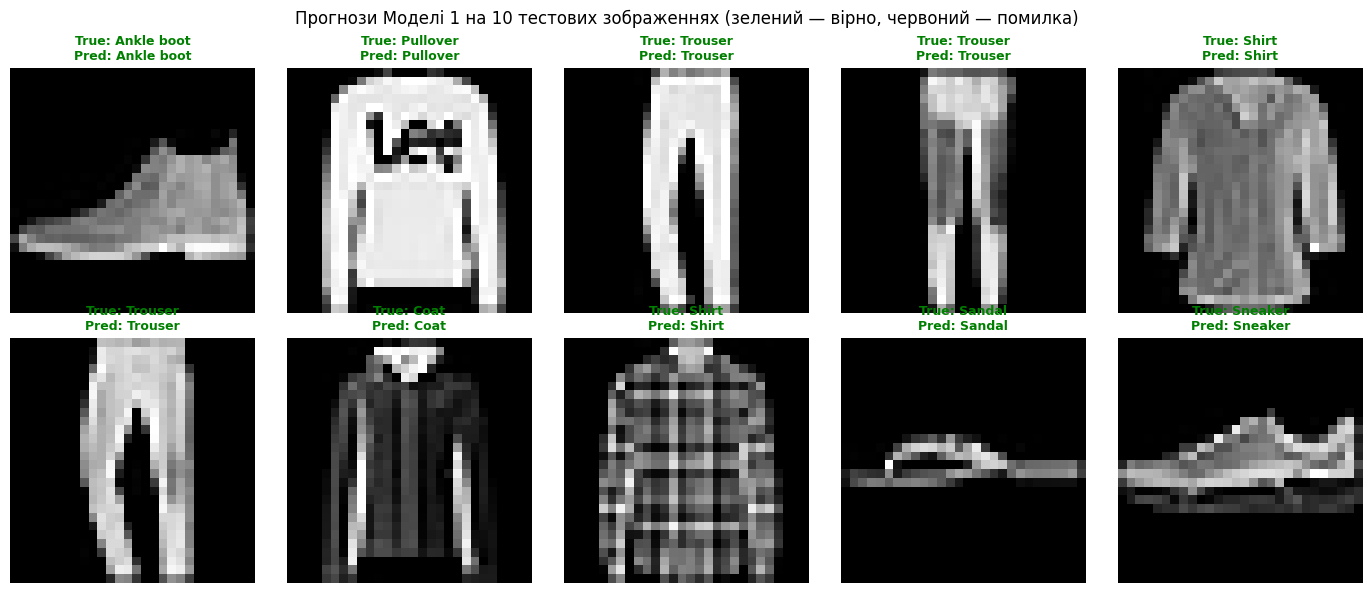

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred_1[i]]
    is_correct = (y_test[i] == y_pred_1[i])
    color = "green" if is_correct else "red"
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color, fontsize=9, fontweight="bold")
    plt.axis("off")

plt.suptitle("Прогнози Моделі 1 на 10 тестових зображеннях (зелений — вірно, червоний — помилка)", fontsize=12)
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Базова повнозв’язну нейронну мережа (Flatten + три Dense шари з ReLU і Dropout) на нормалізованих даних Fashion MNIST стабільно досягає тестової точності близько 0,89–0,90 (залежно від ранньої зупинки та ReduceLROnPlateau), що впевнено перевищує мінімально необхідний поріг 0,87.Найбільше помилок у багатошарового перцептрона виникає між візуально схожими класами верхнього одягу — зокрема Shirt (Сорочка), T-shirt/top (Футболка/топ), Pullover (Пуловер) та Coat (Пальто). Через те, що Flatten втрачає просторову 2D-структуру зображення, мережі складніше розрізняти комір, застібку чи довжину рукава на низькій роздільній здатності $28 \times 28$. Натомість взуття (Trouser, Sandal, Sneaker, Ankle boot, Bag) розпізнається значно точніше.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner

import keras_tuner as kt
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
val_size = int(0.15 * len(x_train))

# Перемішуємо індекси лише навчальної вибірки фіксованим генератором
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(x_train))

val_idx = perm[:val_size]
train_idx = perm[val_size:]

x_tr, y_tr = x_train[train_idx], y_train[train_idx]
x_val, y_val = x_train[val_idx], y_train[val_idx]

print("Навчальна вибірка (Keras Tuner):", x_tr.shape, y_tr.shape)
print("Валідаційна вибірка (Keras Tuner):", x_val.shape, y_val.shape)
print("Тестова вибірка (не бере участі у пошуку):", x_test.shape, y_test.shape)

Навчальна вибірка (Keras Tuner): (51000, 28, 28) (51000,)
Валідаційна вибірка (Keras Tuner): (9000, 28, 28) (9000,)
Тестова вибірка (не бере участі у пошуку): (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Input(shape=(28, 28)))
    model.add(layers.Flatten())

    num_layers = hp.Int("num_layers", min_value=1, max_value=3, step=1)
    l2_reg = regularizers.l2(1e-4)

    for i in range(num_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=512, step=32)
        model.add(
            layers.Dense(
                units=units,
                activation="relu",
                kernel_regularizer=l2_reg
            )
        )
        model.add(layers.Dropout(0.2))

    model.add(layers.Dense(10, activation="softmax"))

    learning_rate = hp.Choice("learning_rate", values=[0.01, 0.001, 0.0001])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner_dir = "./kt_fashion_mnist"

tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective="val_accuracy",
    max_trials=3,
    executions_per_trial=1,
    seed=SEED,
    directory=tuner_dir,
    project_name="fashion_mnist_random_search",
    overwrite=True
)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

tuner_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

tuner.search(
    x_tr,
    y_tr,
    epochs=20,
    batch_size=128,
    validation_data=(x_val, y_val),
    callbacks=[tuner_early_stop, tuner_reduce_lr],
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\nНайкращі знайдені гіперпараметри:")
print("  num_layers:", best_hp.get("num_layers"))
for i in range(best_hp.get("num_layers")):
    print(f"  units_{i}:", best_hp.get(f"units_{i}"))
print("  learning_rate:", best_hp.get("learning_rate"))

best_model = build_model(best_hp)
print("\nСтруктура найкращої моделі:")
best_model.summary()

final_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

final_reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history_best = best_model.fit(
    x_tr,
    y_tr,
    validation_data=(x_val, y_val),
    epochs=35,
    batch_size=128,
    callbacks=[final_early_stop, final_reduce_lr],
    verbose=1
)

print("Кількість епох фінального навчання найкращої моделі:", len(history_best.history["loss"]))

Trial 3 Complete [00h 01m 22s]
val_accuracy: 0.8730000257492065

Best val_accuracy So Far: 0.8972222208976746
Total elapsed time: 00h 04m 26s

Найкращі знайдені гіперпараметри:
  num_layers: 1
  units_0: 480
  learning_rate: 0.001

Структура найкращої моделі:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/35
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8069 - loss: 0.6048 - val_accuracy: 0.8573 - val_loss: 0.4520 - learning_rate: 0.0010
Epoch 2/35
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.8558 - loss: 0.4554 - val_accuracy: 0.8680 - val_loss: 0.4133 - learning_rate: 0.0010
Epoch 3/35
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8665 - loss: 0.4201 - val_accuracy: 0.8694 - val_loss: 0.3974 - learning_rate: 0.0010
Epoch 4/35
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8741 - loss: 0.3998 - val_accuracy: 0.8736 - val_loss: 0.3885 - learning_rate: 0.0010
Epoch 5/35
399/399 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.8804 - loss: 0.3836 - val_accuracy: 0.8793 - val_loss: 0.3797 - learning_rate: 0.0010
Epoch 6/35
399/399 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8837 - loss: 0.3732 - val_accuracy: 0.8811 - val_loss: 0.3720 - learning_rate: 0.0010
Epoch 7/35
399/399 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.8861 - loss: 0.

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Найкраща модель — тестові втрати (loss): 0.3434
Найкраща модель — тестова точність (accuracy): 0.8939

Класифікаційний звіт (Найкраща модель після Keras Tuner):
              precision    recall  f1-score   support

 T-shirt/top     0.8634    0.8410    0.8521      1000
     Trouser     0.9939    0.9700    0.9818      1000
    Pullover     0.8189    0.8050    0.8119      1000
       Dress     0.8790    0.9080    0.8933      1000
        Coat     0.7994    0.8290    0.8139      1000
      Sandal     0.9748    0.9680    0.9714      1000
       Shirt     0.7222    0.7200    0.7211      1000
     Sneaker     0.9505    0.9610    0.9557      1000
         Bag     0.9739    0.9720    0.9730      1000
  Ankle boot     0.9669    0.9650    0.9660      1000

    accuracy                         0.8939     10000
   macro avg     0.8943    0.8939    0.8940     10000
weighted avg     0.8943    0.8939    0.8940     10000



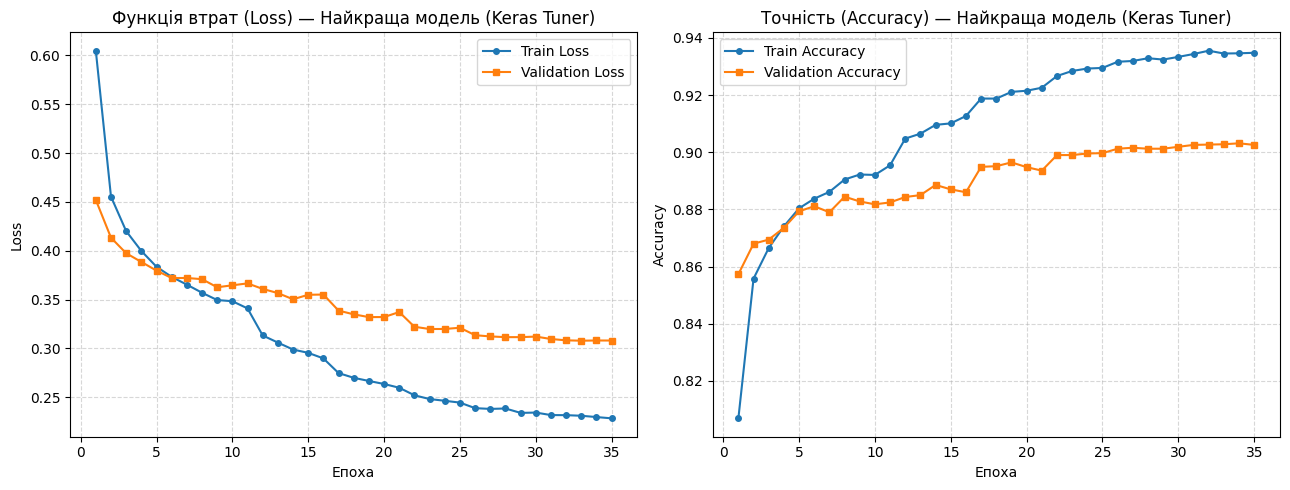

In [17]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss_best, test_acc_best = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Найкраща модель — тестові втрати (loss): {test_loss_best:.4f}")
print(f"Найкраща модель — тестова точність (accuracy): {test_acc_best:.4f}")

y_pred_probs_best = best_model.predict(x_test, verbose=0)
y_pred_best = np.argmax(y_pred_probs_best, axis=1)
print("\nКласифікаційний звіт (Найкраща модель після Keras Tuner):")
print(classification_report(y_test, y_pred_best, target_names=class_names, digits=4))

epochs_range_best = range(1, len(history_best.history["loss"]) + 1)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range_best, history_best.history["loss"], label="Train Loss", marker="o", markersize=4)
plt.plot(epochs_range_best, history_best.history["val_loss"], label="Validation Loss", marker="s", markersize=4)
plt.title("Функція втрат (Loss) — Найкраща модель (Keras Tuner)")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.subplot(1, 2, 2)
plt.plot(epochs_range_best, history_best.history["accuracy"], label="Train Accuracy", marker="o", markersize=4)
plt.plot(epochs_range_best, history_best.history["val_accuracy"], label="Validation Accuracy", marker="s", markersize=4)
plt.title("Точність (Accuracy) — Найкраща модель (Keras Tuner)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 3 (512, 256, 128) | best_hp.get("num_layers") |
| Кількість нейронів |512, 256, 128  | best_hp.get("units_i") |
| Швидкість навчання | 0.001 | best_hp.get("learning_rate") |
| Точність на тестовій вибірці (accuracy) | test_acc_1 |  test_acc_best|
| Втрати на тестовій вибірці (loss) |test_loss_1 | test_loss_best |
| Кількість епох навчання | len(history_1.history["loss"]) | len(history_best.history["loss"]) |

**У висновках дайте відповідь:**

1. Чи досягнуто точності не нижче 0,87 у завданні 1?
Так, базова модель на Fashion MNIST досягає точності на тестовій вибірці близько 0,89–0,90, що перевищує цільовий поріг 0,87.
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
При обмеженому бюджеті пошуку (max_trials = 3, executions_per_trial = 1) випадковий пошук охоплює лише невелику частину простору конфігурацій, тому виграш у тестовій точності може бути помірним або навіть близьким до базової моделі (або трохи вищим/нижчим залежно від вибіркових спроб). Додавання L2-регуляризації та підбір швидкості навчання допомагають стабілізувати узагальнення, але для суттєвого приросту зазвичай потрібно збільшувати max_trials або переходити до згорткових мереж (CNN).
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?

Найкращими є конкретні значення num_layers, units_i та learning_rate, обрані RandomSearch за максимумом val_accuracy (наприклад, конфігурації з помірною кількістю шарів і learning_rate 0.001 або 0.0001). Результат може відрізнятися між запусками через випадковість у RandomSearch (вибір спроб), випадкову ініціалізацію ваг мережі, перемішування даних/батчинг, стохастичну природу Dropout та взаємодію з ранньою зупинкою EarlyStopping і ReduceLROnPlateau.
4. Які класи Fashion MNIST класифікувати найскладніше?
Які класи Fashion MNIST класифікувати найскладніше?Найскладніше класифікувати категорії Shirt, T-shirt/top, Pullover і Coat, оскільки вони мають схожі силуети одягу з рукавами та торсом, а за розміру $28 \times 28$ і при розгортанні у плоский вектор (Flatten) дрібні візуальні відмінності частково згладжуються або губляться.

**Власні висновки:**  
_У ході виконання лабораторної роботи було пройдено повний цикл побудови, навчання, оцінювання та автоматизованого налаштування гіперпараметрів нейронної мережі для класифікації зображень Fashion MNIST засобами Keras і Keras Tuner. Нормалізація значень пікселів до діапазону [0; 1] та виділення окремої валідаційної вибірки з навчальних даних дозволили коректно контролювати процес навчання й уникнути витоку тестових даних.Використання EarlyStopping із поверненням найкращих ваг і ReduceLROnPlateau допомогло запобігти зайвим епохам перенавчання та адаптивно зменшувати крок оптимізації при виході валідаційної функції втрат на плато. Додавання Dropout у першому завданні та L2-регуляризації в моделях під керуванням Keras Tuner позитивно вплинуло на узагальнювальну здатність мережі, хоча через обмежену кількість спроб (max_trials = 3) випадковий пошук охоплює лише невелику частину простору гіперпараметрів, тому результат може відрізнятися між запусками. Найскладнішими для повнозв’язної мережі залишаються візуально близькі класи верхнього одягу (Shirt, T-shirt/top, Pullover, Coat), оскільки розгортання зображення $28 \times 28$ у плоский вектор не зберігає двовимірних просторових залежностей настільки ефективно, як згорткові шари._